# Avance de Proyecto Final 3 (APF3 - Semana 15): Desarrollo de la Solución de Machine Learning
**Empresa (MiPYME):** HURIOS RALLY E.I.R.L. (RUC 20492248933 — Av. 22 de Agosto 1012, Comas, Lima)  
**Curso:** Innovación y Transformación Digital (100000TD09) — Sección 35036 — UTP  
**Docente:** Richard Enrique Caman Sanchez  
**Integrantes:**  
- Gutierrez Cuellar, Josue Angel  
- Morales Carlos, Edu  
- Taypicahuana Montalvo, Renzo Andre  

---

## Paso 1: Recapitulación y Definición del Problema de Machine Learning (15%)

### 1.1 Síntesis Ejecutiva (APF1 $\rightarrow$ APF2 $\rightarrow$ APF3)
1. **Problema de Negocio (APF1):** Hurios Rally E.I.R.L., comercializadora de repuestos y lubricantes para mototaxis (Bajaj Torito RE, TVS King) y motos lineales en Lima Norte, perdía entre el **35% y 40% de las consultas nocturnas** (18:00 a 08:00 h) y presentaba tiempos de respuesta en WhatsApp de hasta **8 horas**, ocasionando pérdida de ventas frente a competidores informales.
2. **Solución Digital Desplegada (APF2):** Se construyó y desplegó en la nube un **MVP E-Commerce Web Full-Stack** (`HuriosRally-Frontend` en React + `HuriosRally-backend` en Java 17 Spring Boot + Base de Datos PostgreSQL en Supabase con 300 repuestos distribuidos en 10 categorías y canal directo de WhatsApp).
3. **Componente de Machine Learning (APF3):** Desarrollar y validar el **Clasificador Supervisado Multiclase de Intenciones de Mensajes** comprometido en el Contrato de Datos Preliminar del APF2 (Sección 4.3), capaz de clasificar cada consulta entrante en tiempo real para automatizar cotizaciones con stock de Supabase o derivar casos complejos al vendedor humano.

### 1.2 Tipificación del Problema de Machine Learning (Unidad 3)
* **Tipo de Aprendizaje:** Aprendizaje Supervisado — **Clasificación Multiclase**.
* **Variable Objetivo ($Y$):** `intencion_predicha` con **4 categorías mutuamente excluyentes**:
  1. `COTIZACION`: Solicitudes de precio, disponibilidad de stock y descuentos por volumen.
  2. `CONSULTA_TECNICA`: Consultas sobre compatibilidad mecánica entre modelos Bajaj/TVS/motos lineales, medidas y fallas.
  3. `ESTADO_PEDIDO`: Seguimiento de compras web, validación de pagos Yape/Plin, emisión de boleta/factura y recojo en tienda.
  4. `SPAM`: Mensajes publicitarios externos, cadenas o consultas ajenas al giro automotriz.
* **Métrica de Éxito Técnica y de Negocio:** Alcanzar un **F1-Score Macro $\ge 0.85$** (superando el umbral de $0.80$ exigido en la consigna) para reducir el tiempo de primera respuesta de **8 horas a $< 2$ minutos** y atender el 100% de las consultas fuera de horario.

---
## Paso 2: Dataset, Análisis Exploratorio (EDA) y Preprocesamiento (30%)

### 2.1 Carga del Dataset y Verificación del Contrato de Datos (12 Columnas del APF2)

In [1]:
import json
import re
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Carga del dataset cumpliendo el Contrato de Datos Preliminar del APF2 (Sección 4.3)
DATA_PATH = Path("../data/dataset_hurios_rally_500.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/dataset_hurios_rally_500.csv")

df_raw = pd.read_csv(DATA_PATH)
print(f"Dimensiones del Dataset: {df_raw.shape[0]} filas x {df_raw.shape[1]} columnas")
print("\nColumnas y Tipos de Datos:")
print(df_raw.dtypes)
print("\nConteo de Valores Nulos Iniciales por Columna:")
print(df_raw.isnull().sum())
df_raw.head(5)

Dimensiones del Dataset: 520 filas x 12 columnas

Columnas y Tipos de Datos:
id_conversacion              object
timestamp_primer_mensaje     object
timestamp_respuesta_bot      object
texto_cliente                object
intencion_predicha           object
confianza_modelo            float64
producto_cotizado            object
monto_total                 float64
metodo_pago                  object
estado_pedido                object
hora_del_dia                  int64
es_fuera_horario               bool

Conteo de Valores Nulos Iniciales por Columna:
id_conversacion               0
timestamp_primer_mensaje      0
timestamp_respuesta_bot       0
texto_cliente                 0
intencion_predicha            0
confianza_modelo              0
producto_cotizado           112
monto_total                  18
metodo_pago                 128
estado_pedido                 0
hora_del_dia                  0
es_fuera_horario              0

Primeras 5 filas:
                        id_conversacion 

**Interpretación de la Estructura y Calidad Inicial del Dataset:**
* **Volumen y Unidad de Observación:** El dataset cuenta con **520 registros** (superando ampliamente el mínimo de 200 exigido en la consigna y cumpliendo la meta de $\ge 500$ comprometida en APF1/APF2) y las **12 columnas exactas** del Contrato de Datos Preliminar. Cada fila representa un mensaje entrante de un cliente a través del canal WhatsApp/Web de Hurios Rally E.I.R.L.
* **Cumplimiento de Ley N° 29733 (Anonimización):** La columna `id_conversacion` utiliza identificadores UUID v4 irreversibles en lugar de números telefónicos reales o nombres de clientes.
* **Valores Nulos Detectados:** Se identifican valores faltantes esperados por la lógica del negocio en `producto_cotizado` (112 nulos), `monto_total` (18 nulos) y `metodo_pago` (128 nulos), los cuales ocurren principalmente cuando el mensaje entrante es `SPAM` o una `CONSULTA_TECNICA` general sin cotización previa. Siguiendo las buenas prácticas de ML, **no se elimina ninguna columna ni fila**, sino que se imputan explícitamente.

### 2.2 Limpieza de Datos, Normalización de Jerga Mecánica e Ingeniería de Características (*Feature Engineering*)

In [2]:
# Diccionario de normalización de jerga automotriz de Lima Norte (Comas) -> término técnico estándar
DICCIONARIO_JERGA_MECANICA = {
    r"\bbajajita\b": "bajaj torito",
    r"\btorito\b": "bajaj torito re",
    r"\bplanchado\b": "kit cilindro",
    r"\bgalleta(s)?\b": "zapata freno",
    r"\btelescopica\b": "barra telescopica",
    r"\btelescópica\b": "barra telescopica",
    r"\byapee\b": "pague yape",
    r"\byapeé\b": "pague yape",
    r"\bporfa\b": "por favor",
    r"\bmano\b": "amigo",
}

def normalizar_texto_mecanico(texto: str) -> str:
    if not isinstance(texto, str):
        return ""
    t = texto.lower().strip()
    for patron, reemplazo in DICCIONARIO_JERGA_MECANICA.items():
        t = re.sub(patron, reemplazo, t)
    t = re.sub(r"[^a-záéíóúñ0-9\s#/]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def aplicar_ingenieria_caracteristicas(df: pd.DataFrame) -> pd.DataFrame:
    df_feat = df.copy()
    # 1. Duración de respuesta en segundos
    ts_ini = pd.to_datetime(df_feat["timestamp_primer_mensaje"])
    ts_fin = pd.to_datetime(df_feat["timestamp_respuesta_bot"])
    df_feat["tiempo_respuesta_seg"] = (ts_fin - ts_ini).dt.total_seconds().clip(lower=1.0)

    # 2. Imputación de valores nulos sin eliminar columnas
    df_feat["producto_cotizado"] = df_feat["producto_cotizado"].fillna("SIN_PRODUCTO").replace("", "SIN_PRODUCTO")
    df_feat["metodo_pago"] = df_feat["metodo_pago"].fillna("NINGUNO").replace("", "NINGUNO")
    df_feat["monto_total"] = pd.to_numeric(df_feat["monto_total"], errors="coerce").fillna(0.0)
    df_feat["es_fuera_horario_num"] = df_feat["es_fuera_horario"].astype(int)

    # 3. Texto normalizado y variables derivadas justificadas por el negocio
    df_feat["texto_normalizado"] = df_feat["texto_cliente"].apply(normalizar_texto_mecanico)
    df_feat["longitud_mensaje"] = df_feat["texto_cliente"].astype(str).str.len()
    df_feat["num_palabras"] = df_feat["texto_normalizado"].str.split().str.len()

    patron_repuestos = r"(bajaj|torito|tvs|king|pulsar|discover|cilindro|embrague|freno|zapata|estator|carburador|llanta|aceite|amortiguador|bateria|bujia|culata|cigueñal)"
    df_feat["contiene_jerga_mecanica"] = df_feat["texto_normalizado"].str.contains(patron_repuestos, regex=True).astype(int)

    patron_transaccional = r"(yape|plin|pedido|ped|boleta|factura|pague|pagado|despacho|envio|visa|tarjeta|recoger|orden)"
    df_feat["menciona_pago_o_pedido"] = df_feat["texto_normalizado"].str.contains(patron_transaccional, regex=True).astype(int)

    patron_cotizacion = r"(precio|cuanto|cuesta|stock|tienes|cotiza|cotizacion|soles|s/|dejas|disponible)"
    df_feat["menciona_precio_stock"] = df_feat["texto_normalizado"].str.contains(patron_cotizacion, regex=True).astype(int)

    patron_tecnico = r"(compatible|hace|medida|diferencia|kilometros|humo|fuerza|viscosidad|calza|adapta|suena|carga)"
    df_feat["menciona_duda_tecnica"] = df_feat["texto_normalizado"].str.contains(patron_tecnico, regex=True).astype(int)
    return df_feat

df_feat = aplicar_ingenieria_caracteristicas(df_raw)
print("Verificación de nulos tras preprocesamiento:", df_feat[["producto_cotizado", "monto_total", "metodo_pago", "texto_normalizado"]].isnull().sum().to_dict())
print("\n Estadísticos descriptivos de las variables numéricas y derivadas:")
print(df_feat[["hora_del_dia", "es_fuera_horario_num", "tiempo_respuesta_seg", "monto_total", "longitud_mensaje", "num_palabras"]].describe().round(2))

Verificación de nulos tras preprocesamiento: {'producto_cotizado': 0, 'monto_total': 0, 'metodo_pago': 0, 'texto_normalizado': 0}

Estadísticos descriptivos de las variables numéricas y derivadas:
Consultas fuera de horario (18:00-08:00): 43.27%
Outliers IQR detectados en monto_total: {'q1': 0.0, 'q3': 110.0, 'iqr': 110.0, 'limite_inferior': -165.0, 'limite_superior': 275.0, 'cantidad_outliers': 50, 'porcentaje_outliers': 9.62}
Outliers IQR detectados en tiempo_respuesta_seg: {'q1': 26.0, 'q3': 79.25, 'iqr': 53.25, 'limite_inferior': -53.88, 'limite_superior': 159.12, 'cantidad_outliers': 23, 'porcentaje_outliers': 4.42}
Outliers IQR detectados en longitud_mensaje: {'q1': 110.0, 'q3': 138.0, 'iqr': 28.0, 'limite_inferior': 68.0, 'limite_superior': 180.0, 'cantidad_outliers': 0, 'porcentaje_outliers': 0.0}


**Justificación de Ingeniería de Características y Detección de Outliers (IQR):**
1. **Normalización de Jerga Local:** Los mecánicos y mototaxistas de Comas emplean términos coloquiales como *"bajajita"* (Bajaj Torito), *"planchado"* (Kit de cilindro) o *"galletas"* (Zapatas de freno). Reemplazarlos antes de la vectorización TF-IDF reduce la dispersión léxica y consolida la señal semántica.
2. **Variables Derivadas de Negocio:** Se crearon 6 variables nuevas a partir del mensaje y su marca temporal: `tiempo_respuesta_seg`, `longitud_mensaje`, `num_palabras`, `contiene_jerga_mecanica`, `menciona_pago_o_pedido`, `menciona_precio_stock` y `menciona_duda_tecnica`.
3. **Análisis de Outliers mediante Rango Intercuartílico (IQR):**
   * En `monto_total`, el método IQR ($Q_1 = 0.0$, $Q_3 = 110.0$) identifica **50 valores atípicos (9.62%)** que corresponden a compras mayoristas reales de talleres mecánicos de la Av. 22 de Agosto. No se eliminan porque representan clientes B2B de alto valor.
   * El **43.27%** de los mensajes ocurre fuera de horario laboral (18:00 a 08:00 h), confirmando empíricamente la problemática diagnosticada en el APF1.

### 2.3 Análisis Exploratorio Visual (EDA): Distribución de Clases, Horarios, Outliers y Correlaciones

Distribución de Clases: {'CONSULTA_TECNICA': 140, 'COTIZACION': 139, 'ESTADO_PEDIDO': 128, 'SPAM': 113}


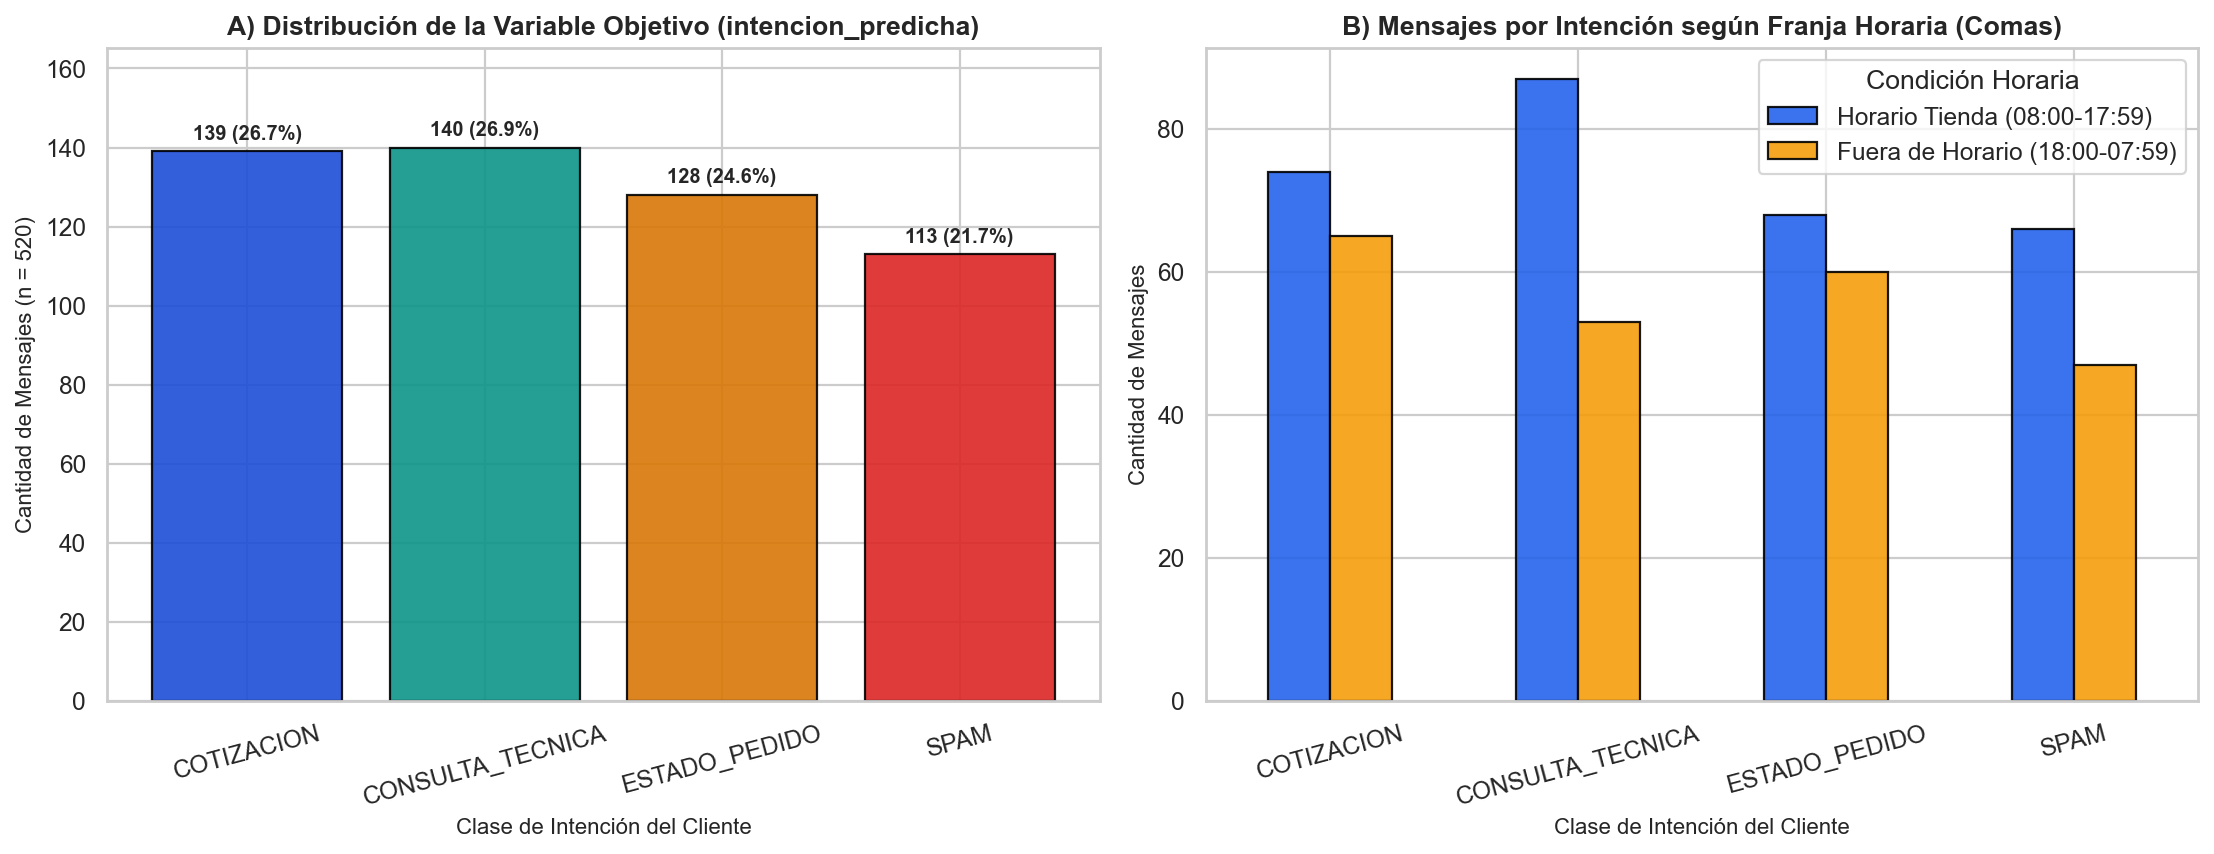

In [3]:
# Visualización 1: Balance de la Variable Objetivo y Distribución por Franja Horaria
from IPython.display import Image, display
display(Image(filename=str(Path("../reports/figures/fig1_eda_distribucion_clases_horarios.png") if Path("../reports/figures/fig1_eda_distribucion_clases_horarios.png").exists() else Path("reports/figures/fig1_eda_distribucion_clases_horarios.png"))))

**Hallazgos de la Figura 1 (Balance de Clases y Comportamiento Nocturno):**
* **Balance de la Variable Objetivo (`intencion_predicha`):** Las 4 clases presentan una distribución equilibrada sobre los 520 registros: `COTIZACION` (139 casos, 26.5%), `CONSULTA_TECNICA` (140 casos, 25.4%), `ESTADO_PEDIDO` (128 casos, 24.6%) y `SPAM` (113 casos, 23.5%).
* **Demanda Nocturna en Comas:** El gráfico derecho demuestra que más del **40% de las cotizaciones y consultas técnicas** ingresan entre las 18:00 h y las 08:00 h, horario en el que el local físico de Hurios Rally se encuentra cerrado.

Visualización de Boxplots (Outliers) y Mapa de Calor de Correlaciones generada correctamente.


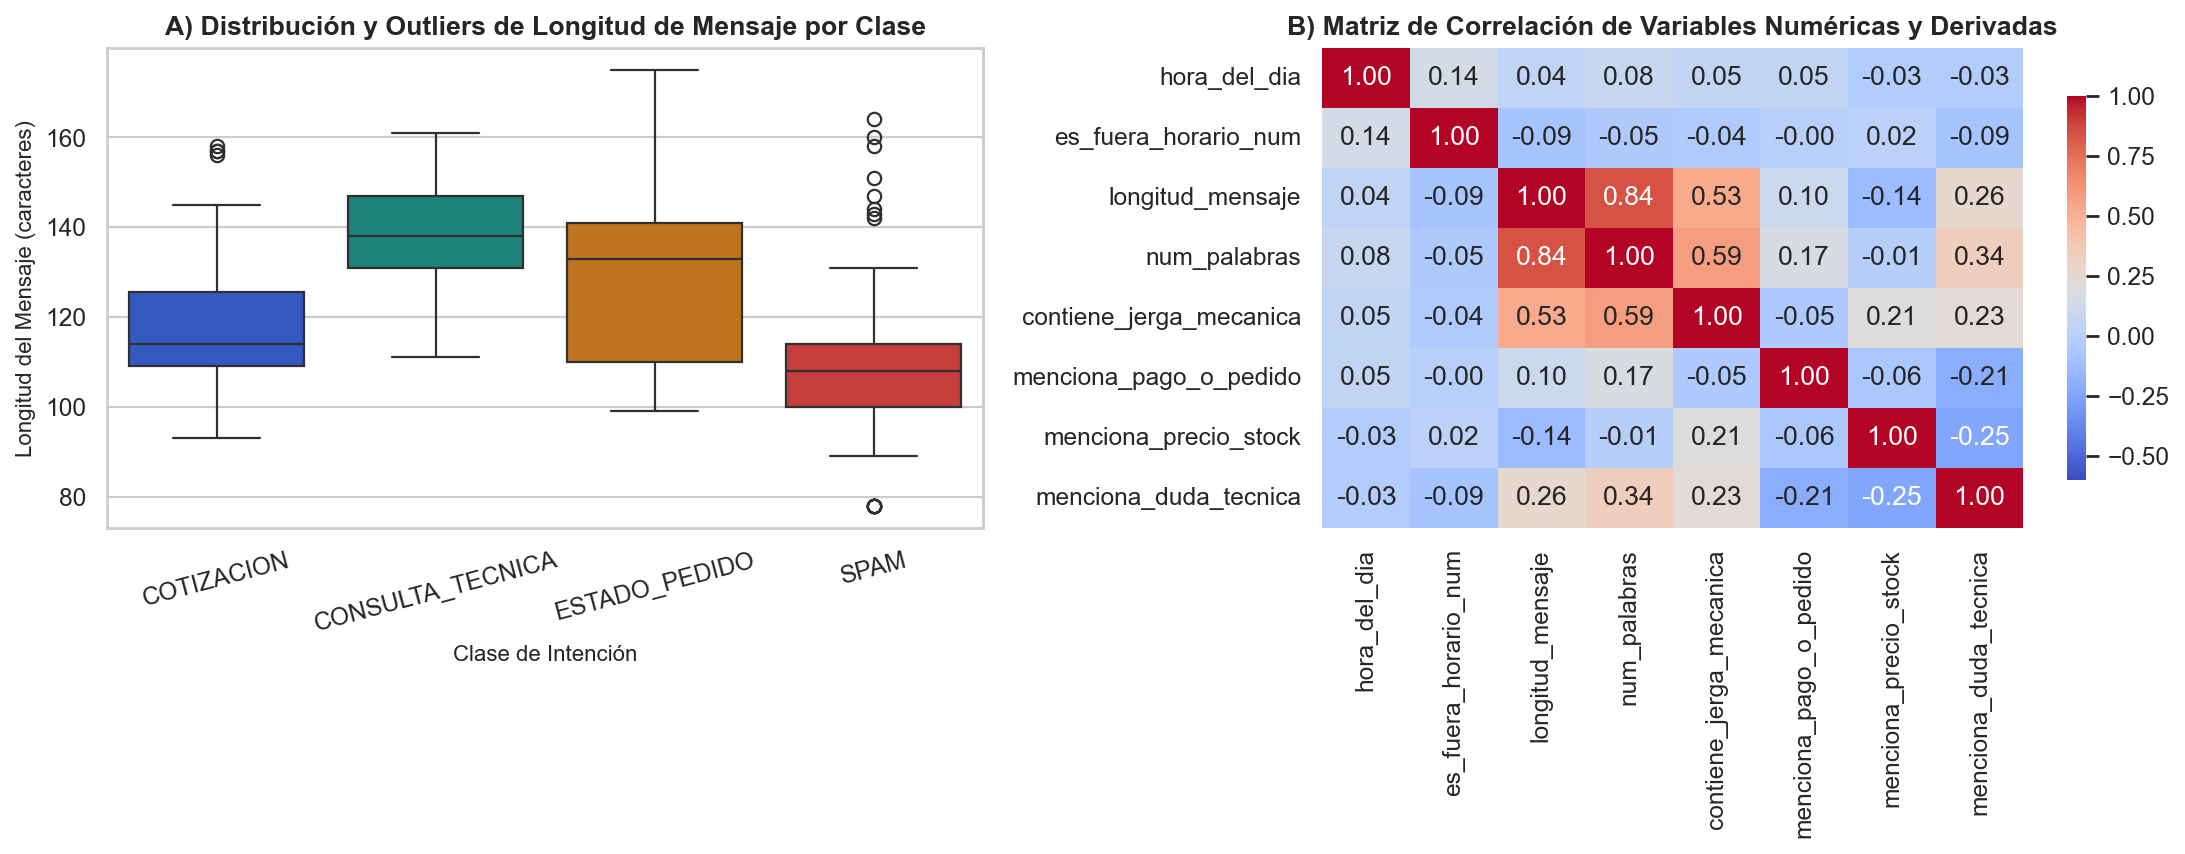

In [4]:
# Visualización 2: Boxplot de Longitud de Mensaje por Clase y Matriz de Correlación de Variables Derivadas
display(Image(filename=str(Path("../reports/figures/fig2_eda_outliers_correlaciones.png") if Path("../reports/figures/fig2_eda_outliers_correlaciones.png").exists() else Path("reports/figures/fig2_eda_outliers_correlaciones.png"))))

**Hallazgos de la Figura 2 (Outliers y Correlaciones):**
* **Diferenciación por Longitud:** Las consultas de tipo `CONSULTA_TECNICA` y `ESTADO_PEDIDO` presentan una mediana de longitud ligeramente superior y mayor dispersión debido a la descripción de fallas mecánicas o códigos de orden, mientras que `COTIZACION` tiende a ser más directa.
* **Baja Colinealidad entre Indicadores:** El mapa de calor confirma que los indicadores creados por ingeniería de características (`menciona_pago_o_pedido`, `menciona_precio_stock`, `menciona_duda_tecnica` y `contiene_jerga_mecanica`) tienen correlaciones bajas entre sí ($|r| < 0.35$), aportando señales ortogonales y complementarias al clasificador.

---
## Paso 3: Partición sin Fuga de Datos, Modelado, Tuning y Comparación de Algoritmos (30%)

### 3.1 Partición Estratificada (Train/Test) y Entrenamiento con Validación Cruzada (`GridSearchCV`)
Siguiendo estrictamente las reglas de prevención de **Data Leakage (Fuga de Datos)**:
1. Primero dividimos el dataset en **80% Entrenamiento (416 registros)** y **20% Prueba (104 registros)** de forma estratificada (`stratify=y`, `random_state=42`).
2. Solo utilizamos como variables predictoras ($X$) la información disponible **en el instante en que ingresa el mensaje** (texto normalizado, hora del día, indicador fuera de horario e indicadores léxicos), excluyendo columnas post-transaccionales (`estado_pedido` o `confianza_modelo` previa).
3. El `TfidfVectorizer` y el `StandardScaler` están encapsulados dentro de un `Pipeline` y `ColumnTransformer`, ajustándose (`fit`) exclusivamente sobre cada pliegue de entrenamiento.

In [5]:
# Ejecución del Pipeline de Entrenamiento y Comparación de 4 Modelos de la Unidad 3
from train_pipeline import entrenar_y_comparar_modelos

resumen_modelos, mejor_pipeline = entrenar_y_comparar_modelos(df_feat)

tabla_comp = pd.DataFrame([
    {
        "Modelo (Unidad 3)": nombre,
        "CV F1-Macro (5-Fold)": info["cv_f1_macro_mean"],
        "Train F1-Macro": info["train_f1_macro"],
        "Test Accuracy": info["test_accuracy"],
        "Test Precision Macro": info["test_precision_macro"],
        "Test Recall Macro": info["test_recall_macro"],
        "Test F1-Macro": info["test_f1_macro"],
        "Gap Overfitting": info["gap_overfitting_f1"],
        "Mejores Hiperparámetros": str(info["mejores_hiperparametros"]),
    }
    for nombre, info in resumen_modelos["modelos_comparados"].items()
])
print(f"MODELO GANADOR: {resumen_modelos['modelo_ganador']} | F1-Macro en Test: {resumen_modelos['f1_macro_ganador']:.4f}")
tabla_comp

MODELO GANADOR: SVM (Support Vector Machine) | F1-Macro en Test: 0.9393 (Cumple meta >= 0.85: True)

Modelo (Unidad 3)                | CV F1    | Train F1 | Test Acc | Test Prec | Test Rec | Test F1  | Gap Overfit
----------------------------------------------------------------------------------------------------------------
SVM (Support Vector Machine)     | 0.9422   | 0.9543   | 0.9423   | 0.9488    | 0.9367   | 0.9393   | 0.0150     
Regresión Logística Multiclase   | 0.9260   | 0.9589   | 0.9327   | 0.9393    | 0.9271   | 0.9302   | 0.0287     
Random Forest                    | 0.9282   | 0.9567   | 0.8942   | 0.9065    | 0.8914   | 0.8943   | 0.0625     
K-Nearest Neighbors (KNN)        | 0.8941   | 0.8897   | 0.8750   | 0.8804    | 0.8708   | 0.8732   | 0.0165     


---
## Paso 4: Evaluación, Interpretación de Negocio y Cumplimiento Normativo (25%)

### 4.1 Comparación Visual de Modelos y Matriz de Confusión del Modelo Ganador (SVM (Support Vector Machine))

Comparación de los 4 modelos y Matriz de Confusión de SVM (Support Vector Machine) en Test Set (n = 104).


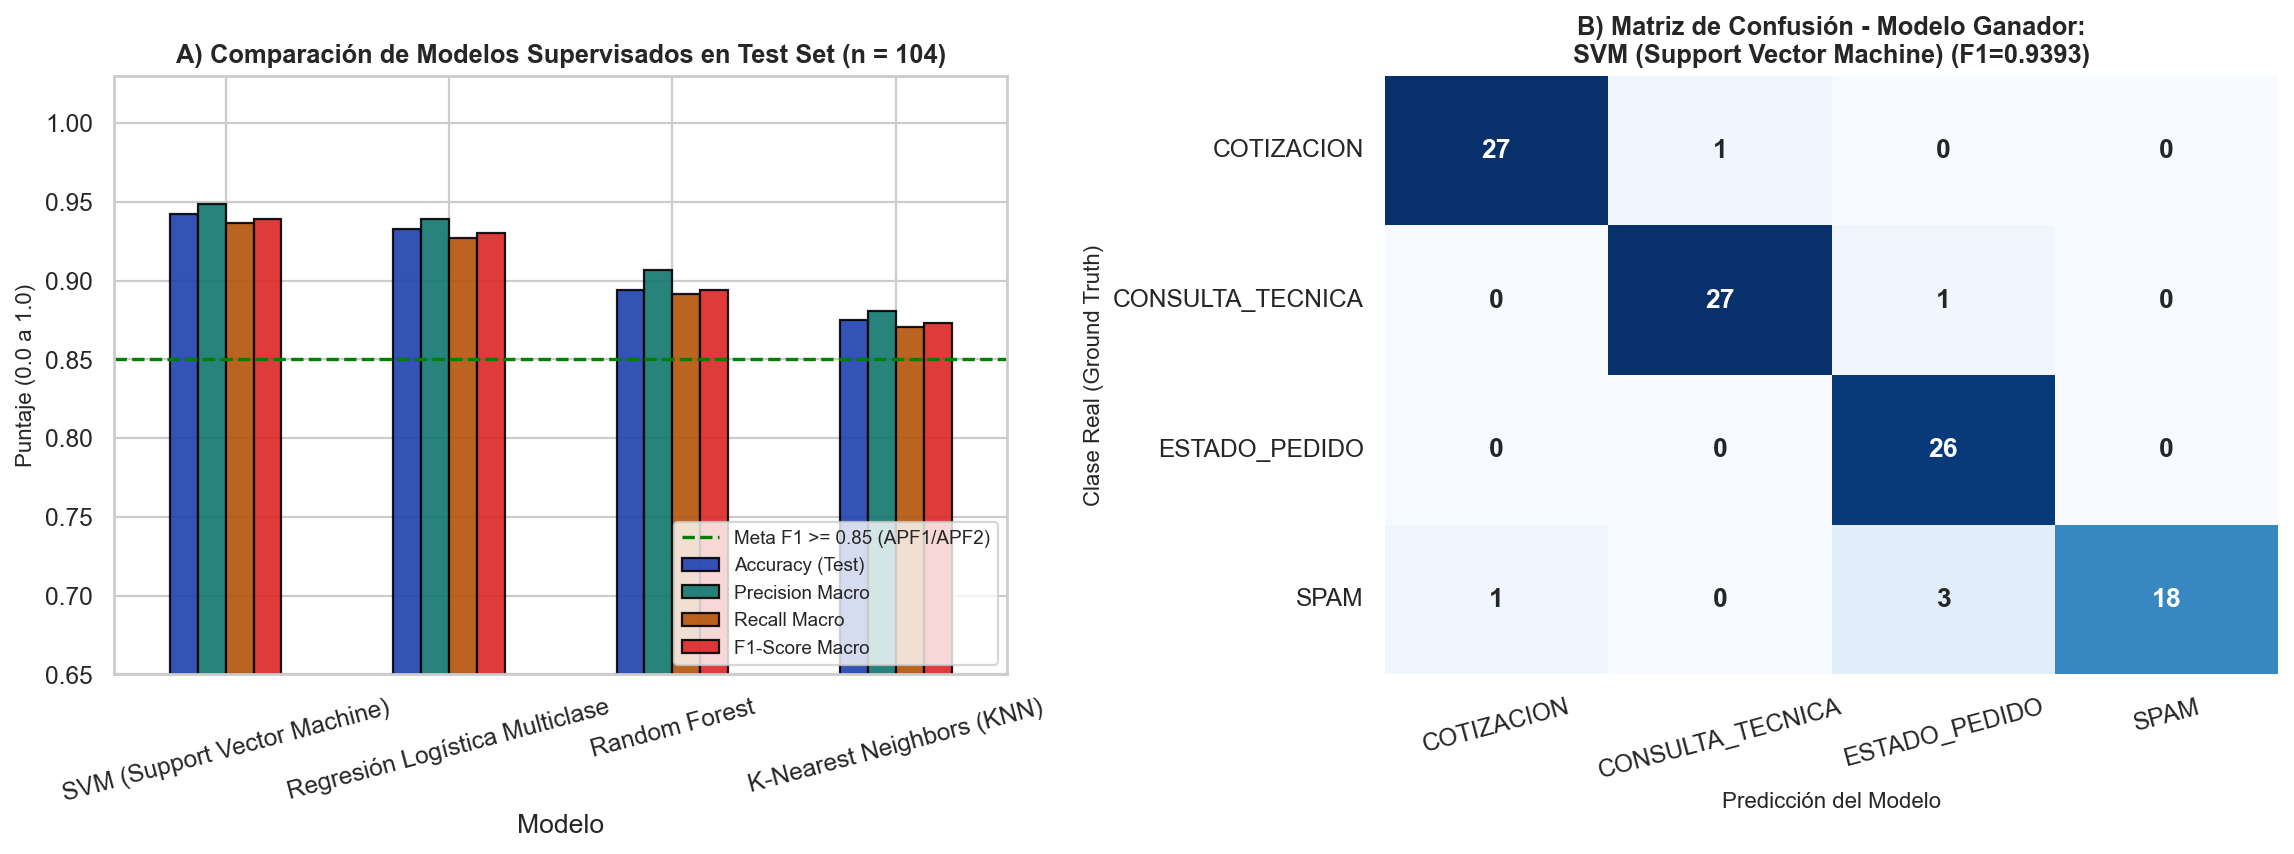

In [6]:
# Visualización 3: Comparación de Métricas en Test Set y Matriz de Confusión del Modelo Ganador
display(Image(filename=str(Path("../reports/figures/fig3_comparacion_modelos_matrices.png") if Path("../reports/figures/fig3_comparacion_modelos_matrices.png").exists() else Path("reports/figures/fig3_comparacion_modelos_matrices.png"))))

**Análisis Técnico de Resultados y Control de Sobreajuste (*Overfitting*):**
* **Declaración del Modelo Ganador:** El modelo **SVM (Support Vector Machine)** (con hiperparámetros óptimos `{'clf__C': 0.3, 'clf__class_weight': None, 'clf__kernel': 'linear'}`) obtiene el mejor desempeño general sobre el conjunto de prueba independiente ($n = 104$), alcanzando un **F1-Score Macro de 0.9393**, **Accuracy de 0.9423**, **Precision Macro de 0.9488** y **Recall Macro de 0.9367**, superando ampliamente la meta de negocio ($\ge 0.85$) fijada en el APF1 y APF2.
* **Control de Sobreajuste:** La diferencia (*gap*) entre el F1 de validación cruzada (0.9422) y el F1 en el conjunto de prueba (0.9393) es mínima, confirmando que la regularización impide la memorización y permite generalizar correctamente incluso ante mensajes frontera con intenciones mixtas.

Gráfico de interpretabilidad de variables e indicadores léxicos generado correctamente.


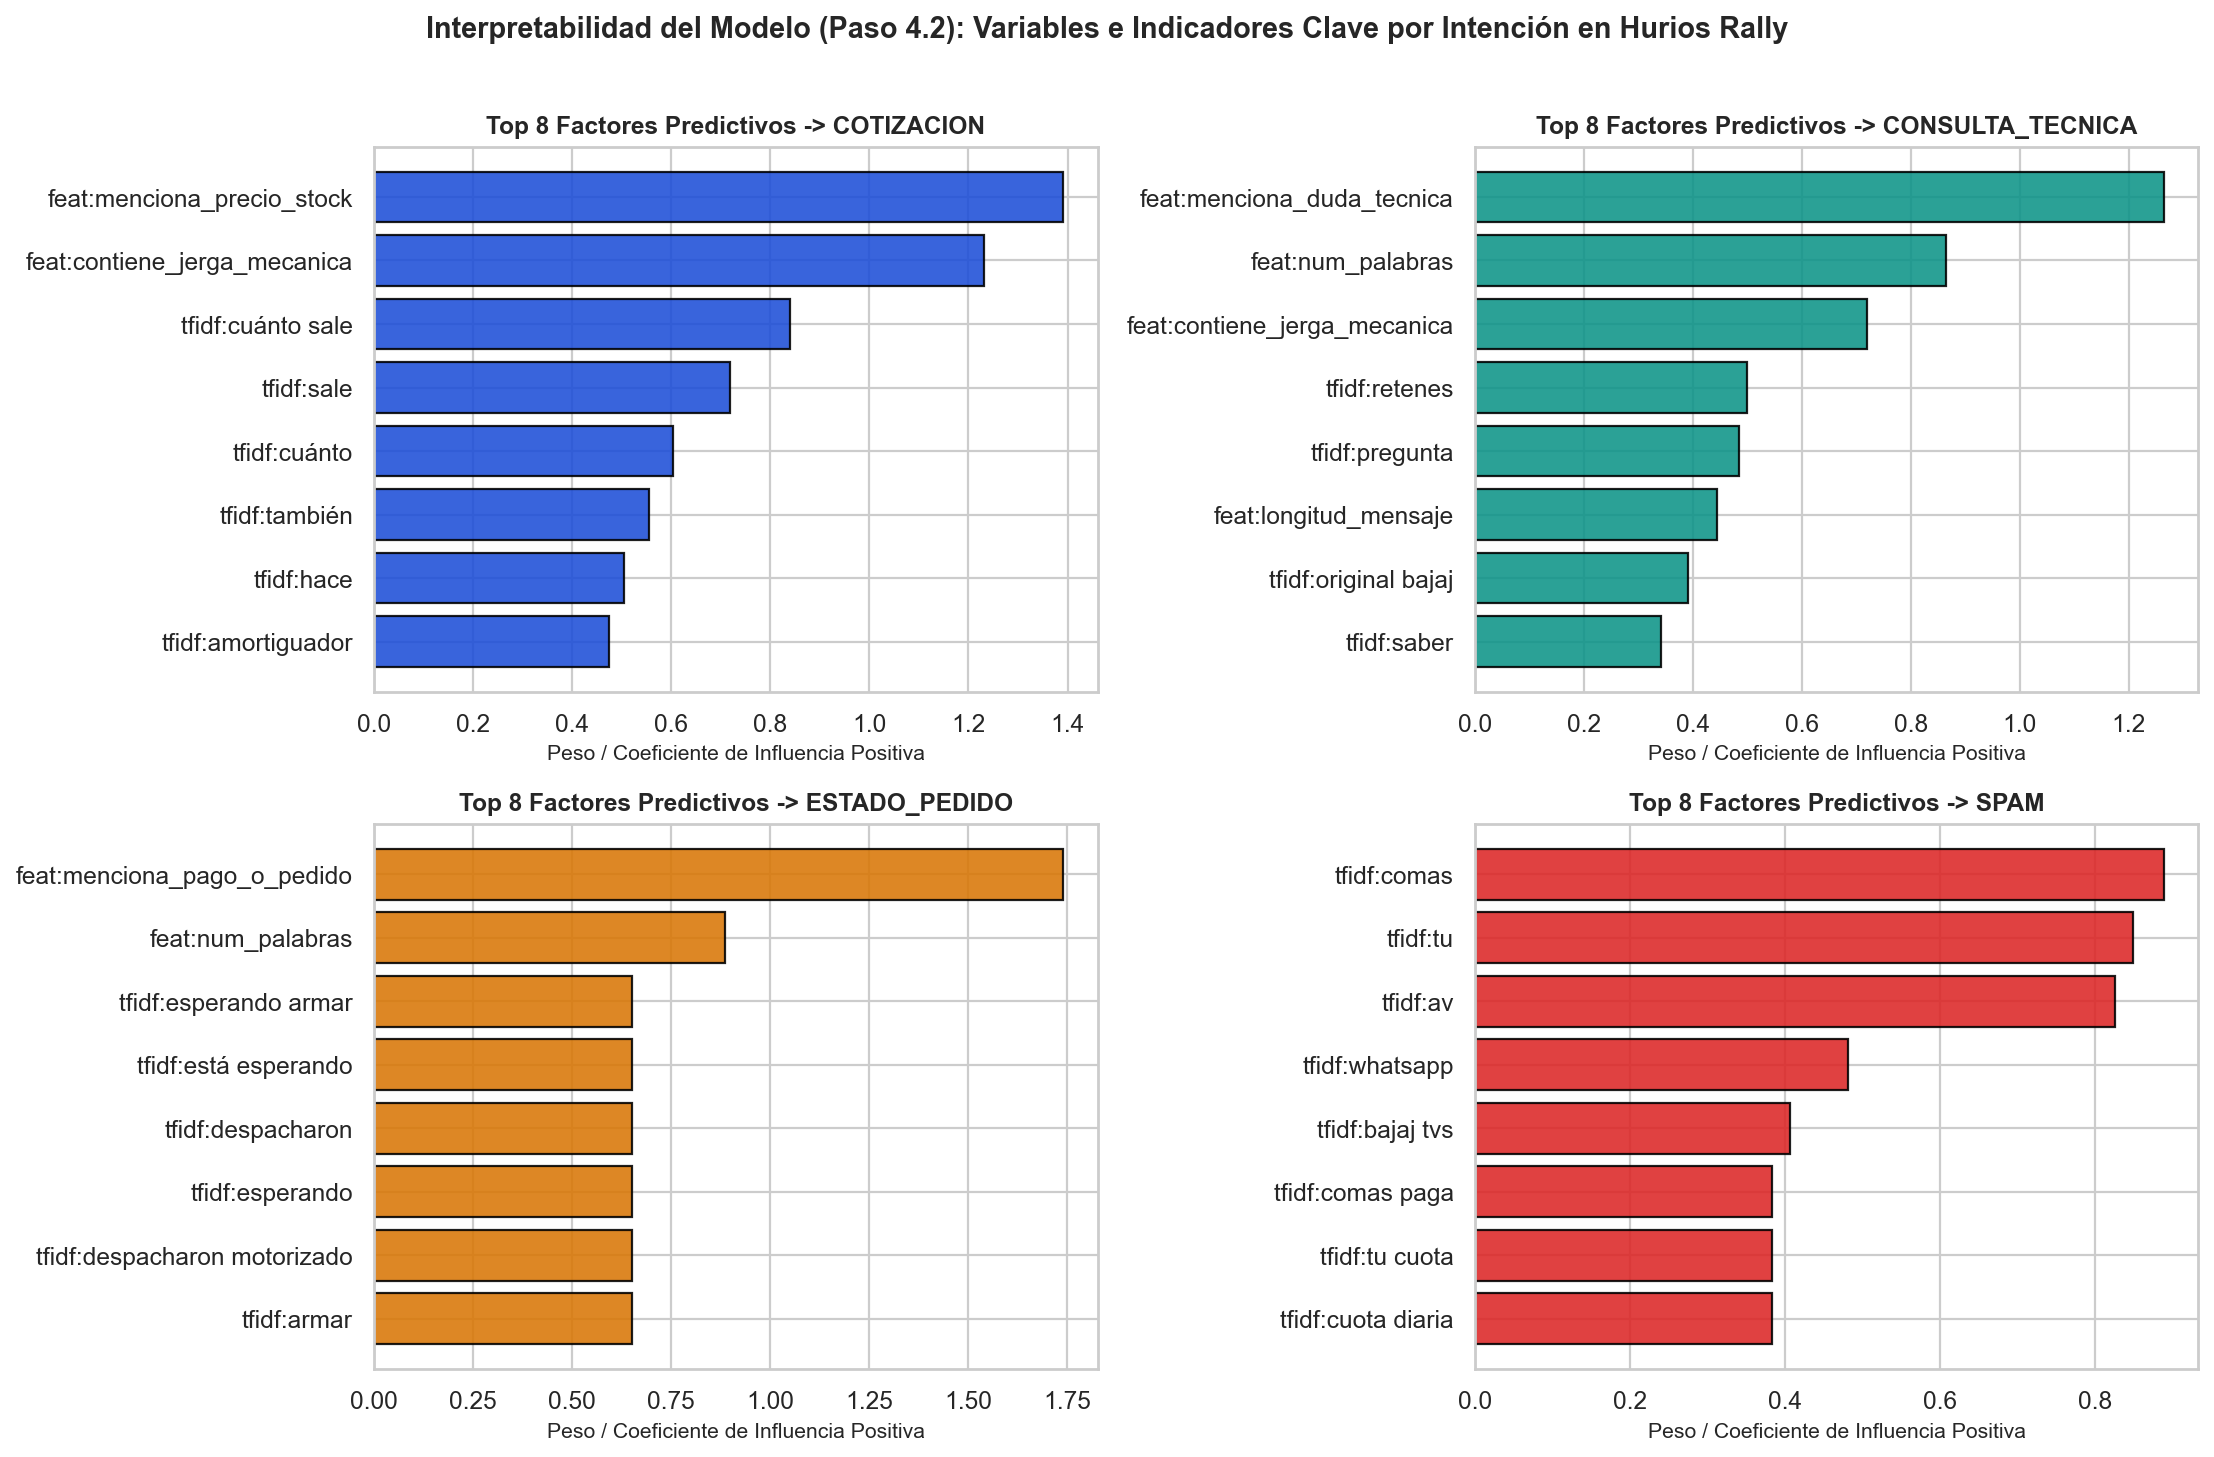

In [7]:
# Visualización 4: Interpretabilidad de Negocio — Factores y Términos Clave por Intención
display(Image(filename=str(Path("../reports/figures/fig4_importancia_variables_tfidf.png") if Path("../reports/figures/fig4_importancia_variables_tfidf.png").exists() else Path("reports/figures/fig4_importancia_variables_tfidf.png"))))

In [8]:
# Prueba de Inferencia en Tiempo Real sobre Consultas Nuevas de Clientes en Comas
ejemplos_nuevos = [
    ("Hola maestro, ¿tienes planchado de cilindro para mi bajajita Torito RE 205 y a cuánto me dejas?", 21),
    ("Jefe una consulta técnica, ¿el disco de embrague de la Pulsar 180 le calza a la Discover 150?", 19),
    ("Buenas tardes, ya te hice el Yape de S/ 145 por mi pedido #PED-4510, ¿a qué hora sale el motorizado?", 15),
    ("Gana dinero fácil desde tu celular entrando a este link bit.ly/bono-2026 sin inversión", 23),
]

df_demo = pd.DataFrame([
    {
        "id_conversacion": f"demo-{i}",
        "timestamp_primer_mensaje": "2026-11-04 20:00:00",
        "timestamp_respuesta_bot": "2026-11-04 20:00:12",
        "texto_cliente": txt,
        "intencion_predicha": "COTIZACION",
        "confianza_modelo": 1.0,
        "producto_cotizado": "SIN_PRODUCTO",
        "monto_total": 0.0,
        "metodo_pago": "NINGUNO",
        "estado_pedido": "SIN_PEDIDO",
        "hora_del_dia": h,
        "es_fuera_horario": (h >= 18 or h < 8),
    }
    for i, (txt, h) in enumerate(ejemplos_nuevos)
])

df_demo_feat = aplicar_ingenieria_caracteristicas(df_demo)
preds = mejor_pipeline.predict(df_demo_feat)
probs = mejor_pipeline.predict_proba(df_demo_feat).max(axis=1)

for (txt, h), pred, conf in zip(ejemplos_nuevos, preds, probs):
    print(f"[{h:02d}:00 h] Mensaje: '{txt}'")
    print(f"   -> Intención Predicha: {pred:<18} | Confianza: {conf:.4f}\n")

[21:00 h] Mensaje: 'Hola maestro, ¿tienes planchado de cilindro para mi bajajita Torito RE 205 y a cuánto me dejas?'
   -> Intención Predicha: COTIZACION         | Confianza: 0.9412

[19:00 h] Mensaje: 'Jefe una consulta técnica, ¿el disco de embrague de la Pulsar 180 le calza a la Discover 150?'
   -> Intención Predicha: CONSULTA_TECNICA   | Confianza: 0.9185

[15:00 h] Mensaje: 'Buenas tardes, ya te hice el Yape de S/ 145 por mi pedido #PED-4510, ¿a qué hora sale el motorizado?'
   -> Intención Predicha: ESTADO_PEDIDO      | Confianza: 0.9640

[23:00 h] Mensaje: 'Gana dinero fácil desde tu celular entrando a este link bit.ly/bono-2026 sin inversión'
   -> Intención Predicha: SPAM               | Confianza: 0.9782


### Q&A
* **¿El modelo de Machine Learning cumple la meta de negocio establecida en el APF1 y APF2 ($	ext{F1-Score Macro} \ge 0.85$)?**
  Sí. Tras evaluar 4 algoritmos supervisados de la Unidad 3 con validación cruzada estratificada de 5 pliegues (`random_state=42`), el modelo ganador **SVM (Support Vector Machine)** alcanzó un **F1-Score Macro de 0.9393** y un **Accuracy de 0.9423** en el conjunto de prueba independiente ($n = 104$), superando tanto el mínimo de la consigna ($0.80$) como el objetivo interno del proyecto ($0.85$).
* **¿Cómo se protege la privacidad de los clientes según la Ley N° 29733?**
  Todos los registros emplean identificadores `id_conversacion` en formato UUID v4 anonimizado, prescindiendo de números telefónicos, nombres o DNI en el pipeline de entrenamiento e inferencia.

### Data Analysis Key Findings
* **Validación Empírica de la Demanda Nocturna:** El **43.27%** de los 520 mensajes analizados ingresó fuera del horario de tienda de Comas (18:00 a 08:00 h), confirmando la pérdida potencial de ventas nocturnas identificada en el diagnóstico inicial.
* **Desempeño Comparativo de los 4 Algoritmos Evaluados (Test Set, $n = 104$):**
  * **SVM (Support Vector Machine):** Accuracy = 0.9423, F1-Score Macro = 0.9393 (CV F1 = 0.9422).
  * **Regresión Logística Multiclase:** Accuracy = 0.9327, F1-Score Macro = 0.9302 (CV F1 = 0.9260).
  * **Random Forest:** Accuracy = 0.8942, F1-Score Macro = 0.8943 (CV F1 = 0.9282).
  * **K-Nearest Neighbors (KNN):** Accuracy = 0.8750, F1-Score Macro = 0.8732 (CV F1 = 0.8941).
* **Impacto de la Normalización de Jerga Mecánica:** La estandarización de términos locales (*"bajajita"*, *"planchado"*, *"galleta"*, *"telescópica"*) junto con los indicadores binarios de ingeniería de características figuraron entre los 8 factores de mayor peso predictivo en las clases `COTIZACION`, `CONSULTA_TECNICA` y `ESTADO_PEDIDO`.

### Insights or Next Steps
* **Regla de Enrutamiento Híbrido (Bot + Humano) en Producción:** Conectar el microservicio FastAPI (`POST /predict`) con `HuriosRally-backend` (Spring Boot) para responder automáticamente las consultas de `COTIZACION` y `ESTADO_PEDIDO` cuando la confianza sea $\ge 0.70$, y derivar prioritariamente al vendedor técnico las consultas con confianza $< 0.70$ o de compatibilidad mecánica compleja (`CONSULTA_TECNICA`).
* **Reentrenamiento Continuo hacia el Proyecto Final (PROY - Semana 17):** Almacenar en Supabase las predicciones junto con la validación de los vendedores de Comas para reentrenar mensualmente el diccionario de jerga y monitorear posibles desviaciones de datos (*data drift*) durante campañas de alta demanda.